**Part 1**

In [11]:
# import libraries
import re
import urllib.request
import requests
from bs4 import BeautifulSoup
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# set up sentiment analysis
import nltk
nltk.download('vader_lexicon')
from nltk.sentiment import SentimentIntensityAnalyzer

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /Users/sebastian/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [14]:
# load image
image_path = "medmnist_xray_grid.png"
img = Image.open(image_path)
img_array = np.array(img)

print(f"Original grid shape: {img_array.shape}")

# split image
n_rows = 10
n_cols = 10
h = img_array.shape[0] // n_rows
w = img_array.shape[1] // n_cols

Original grid shape: (1120, 1120)


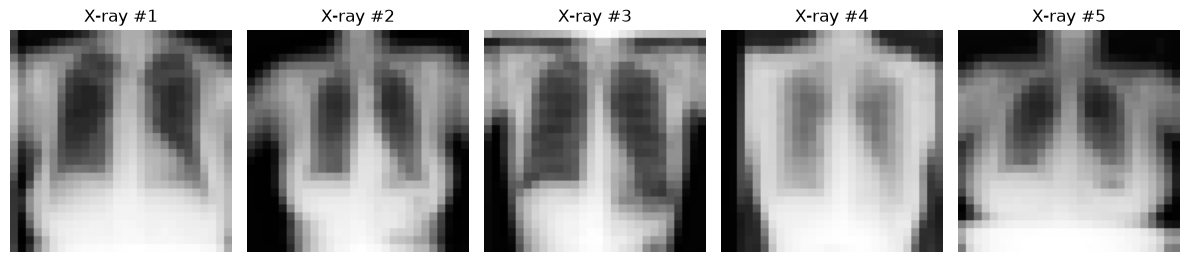

In [18]:
# individual xrays
xrays = []
for r in range(n_rows):
    for c in range(n_cols):
        patch = img_array[r * h : (r + 1) * h, c * w : (c + 1) * w]
        xrays.append(patch)

# convert to numpy array
xrays = np.array(xrays)

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i in range(5):
    axes[i].imshow(xrays[i], cmap='gray' if xrays.ndim == 3 else None)
    axes[i].set_title(f"X-ray #{i+1}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

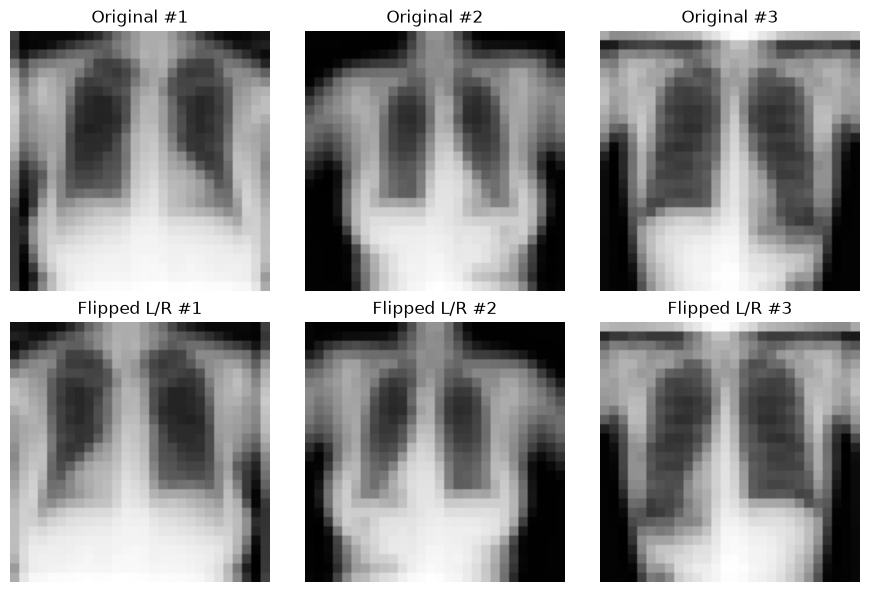

In [ ]:
# horizontal flip
xrays_flipped = np.flip(xrays, axis=2)

fig = plt.figure(figsize=(9, 6))
axes = fig.subplots(nrows=2, ncols=3)

for i in range(3):
    # og
    axes[0, i].imshow(xrays[i], cmap='gray' if xrays.ndim == 3 else None)
    axes[0, i].set_title(f"Original #{i+1}")
    axes[0, i].axis('off')
    
    # horizontal flipped
    axes[1, i].imshow(xrays_flipped[i], cmap='gray' if xrays.ndim == 3 else None)
    axes[1, i].set_title(f"Flipped L/R #{i+1}")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

**Part 2**

In [ ]:
# get text
url = "https://www.gutenberg.org/files/1260/1260-h/1260-h.htm"
req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})

# read html
with urllib.request.urlopen(req) as response:
    raw_html = response.read().decode('utf-8', errors='ignore')